[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tnecniv-Teikram/hyperspectral-course-2026/blob/main/20_geoai_deep_learning.ipynb)

*Running in Colab? Run the setup cell below first — it clones the course and installs what this notebook needs. Running locally? It does nothing.*

# 🤖 GeoAI for Hyperspectral Data — Deep Learning for Classification & Mapping
### Space Academy 2026 · Hyperspectral course · Week 3 — GeoAI methods for hyperspectral applications (Lecture) · AI-assisted hyperspectral classification and mapping (Practical)

In Week 2 you classified Tanager pixels with thresholds and classical machine learning. This notebook moves to
**deep learning**: we train two neural networks on real Tanager data from the mangrove coast of El Salvador,
compare them honestly with a Random Forest baseline, turn the model into a **map with an uncertainty layer**, run
**tiled inference** over the full scene, and test what happens when the model is moved to a **different place**.

**What you will learn**
- The main families of GeoAI models for hyperspectral data: pixel (spectral), patch (spectral–spatial) and
  scene/segmentation models, plus foundation models and self-supervised learning
- Why *spatial* train/validation/test splits are essential for honest accuracy numbers
- How to build and train a **1D-CNN** (spectra only) and a **HybridSN-style 3D→2D CNN** (spectral–spatial patches) in PyTorch
- How to deal with class imbalance (class-weighted loss) and overfitting (early stopping)
- How to produce a map, a confidence map and an **MC-dropout** uncertainty map
- How to run **sliding-window (tiled) inference** over a whole scene and export a Cloud-Optimised GeoTIFF
- Why models degrade under **domain shift** (new region, new scene) — and what to do about it

**Prerequisites:** notebooks 11 (preprocessing), 13 (feature extraction / PCA) and 15 (classical classification).
Basic Python. No prior deep-learning experience is assumed, but this notebook *uses* the mechanics taught in
the lecture — section 2 of `slides/w3a_geoai_methods.pptx`, "How a network actually learns": layers and
weights, the loss, one gradient step, epoch vs batch, dropout and batch normalisation, and how to read a
training curve. Work through those slides first if those terms are new. The aim here is that you can
**run, read and adjust** the training — not write a network from scratch.

**Data**
| Role | Scene ID | Place |
|---|---|---|
| Training / testing | `20250223_165546_32_4001` | Usulután, El Salvador — mangroves, estuary, tropical trees, sugar cane |
| Domain-shift test | `20250407_035509_25_4001` | Ho Chi Minh City, Vietnam |

Labels come from **ESA WorldCover 2021** (10 m), aggregated to the Tanager 30 m grid (`data/labels/`).
`hu.get_scene()` finds the local HDF5 or downloads it (~1 GB) from Planet's open STAC catalogue.

⏱️ Runtime: about 5–8 minutes on a laptop CPU. A GPU is **not** required (on Colab, a GPU runtime makes it faster).

In [ ]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this clones the course repository, installs the geospatial packages that Colab
# does not ship, and moves into the course folder so the notebook finds hsi_utils and data/.
# Locally it does nothing at all — your own environment is already active.
import os
import pathlib
import subprocess
import sys

REPO = "Tnecniv-Teikram/hyperspectral-course-2026"          # change with: python tools/set_repo_url.py <owner>/<repo>

if "google.colab" in sys.modules:
    course = pathlib.Path("/content/hyperspectral-course")
    if not course.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q",
                        f"https://github.com/{REPO}.git", str(course)], check=True)
    os.chdir(course)
    sys.path.insert(0, str(course))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "h5py", "rasterio", "rioxarray", "xarray", "geopandas"], check=True)
    print("Colab ready — course at", course)
else:
    print("Local environment:", sys.executable.split("/")[-3])


In [1]:
# On Google Colab: upload hsi_utils.py next to this notebook and uncomment:
# %pip install -q h5py numpy scipy matplotlib scikit-learn pandas rasterio xarray rioxarray requests torch
import copy
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from numpy.lib.stride_tricks import sliding_window_view
from scipy.ndimage import maximum_filter, minimum_filter
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

import hsi_utils as hu

plt.rcParams["figure.dpi"] = 90
SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)          # keep the laptop responsive; raise on a bigger machine
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
T_START = time.time()
print("PyTorch", torch.__version__, "| device:", DEVICE)

PyTorch 2.14.0 | device: cpu


## 1. Lecture: GeoAI methods for hyperspectral data

### 1.1 Three ways to look at a hyperspectral cube

| Model family | Input | Typical architectures | Strengths | Weaknesses |
|---|---|---|---|---|
| **Pixel / spectral** | one spectrum (≈ 350 values) | Random Forest, SVM, 1D-CNN, spectral transformers (e.g. SpectralFormer, Hong et al. 2022) | Simple, needs few labels, easy to apply to any scene | Ignores spatial context → "salt-and-pepper" maps |
| **Patch / spectral–spatial** | a small cube around a pixel (e.g. 9 × 9 × bands) | 2D-CNN on PCA bands, 3D-CNN (Chen et al. 2016), HybridSN (Roy et al. 2020), vision transformers | Uses texture and neighbourhood → smoother, often more accurate maps | Leakage risk in evaluation, more compute, mixes class boundaries |
| **Scene / segmentation** | a whole tile (e.g. 128 × 128 × bands) | Fully convolutional networks, U-Net, segmentation transformers | Dense output, learns object shapes | Needs *dense* labels — rare for hyperspectral data |

**Why not always use the biggest model?** Hyperspectral classification is usually **label-limited**: a few thousand
labelled pixels, often from a handful of fields. Deep networks with 10⁵–10⁶ parameters overfit easily, so a
well-tuned Random Forest is a strong baseline. Always report it next to your deep model.

### 1.2 Foundation models and self-supervised learning

A **foundation model** is pre-trained on a very large *unlabelled* archive with a **self-supervised** task —
for example reconstructing masked-out patches (masked autoencoders) or matching two views of the same place
(contrastive learning). You then **fine-tune** it, or train a small classifier on its embeddings, with few labels.

Examples you will meet in the literature (the field moves fast; check the latest versions):
- **HyperSIGMA** (Wang et al., 2024/25) — pre-trained on a large archive of spaceborne *hyperspectral* images (EO-1 Hyperion and GaoFen-5).
- **SpectralEarth** (Braham et al., 2024/25) — a large pre-training dataset of *EnMAP* patches, released with pre-trained backbones.
- **SpectralGPT** (Hong et al., 2024) — despite its name, pre-trained on *Sentinel-2 multispectral* data.
- **Prithvi** (NASA & IBM, Jakubik et al., 2023) — *multispectral*, trained on Harmonized Landsat–Sentinel-2 (6 bands).
- **Wavelength-aware models** such as DOFA (Xiong et al., 2024) condition the network on each band's central wavelength, so one model can ingest sensors with different band sets.

⚠️ **Sensor mismatch matters.** A model pre-trained on Sentinel-2 or EnMAP has never seen Tanager's 426-band
grid. You must either resample Tanager to the model's bands (`hu.resample_to_sensor`, notebook 30) or use a
wavelength-aware model. At the time of writing, few (if any) public foundation models are trained on Tanager itself.

### 1.3 Two things that make Earth-observation ML different

1. **Spatial autocorrelation.** Neighbouring pixels look alike. If training and test pixels are interleaved,
   the test set is not independent and accuracy is *inflated* (Roberts et al. 2017; Ploton et al. 2020).
   ➜ Split by **spatial blocks**, and add a **buffer** when models look at neighbourhoods (patches).
2. **Domain shift.** Illumination, atmosphere, season, soil background and even *class definitions* change
   between scenes. A model that is 90 % accurate in one scene can be far worse in another (Section 11).

### 1.4 The plan for this practical

```
El Salvador cube (400×400 px, 352 good bands) + WorldCover labels (pure pixels only)
        │
        ├── spatial block split (train / val / test) + buffer
        ├── Random Forest baseline ─────────────┐
        ├── 1D-CNN on spectra ──────────────────┼──► per-class F1 on the TEST blocks
        └── PCA(30) → 9×9 patches → 3D-CNN ─────┘
                 │
                 ├── maps + confidence + MC-dropout uncertainty
                 ├── tiled inference on the full scene → COG
                 └── domain shift: rest of the scene & Ho Chi Minh City
```

## 2. Data: a Tanager window and WorldCover labels

We work on a 400 × 400 pixel window (12 × 12 km) that contains all five target classes. The cube is read with
the 352 *good* bands (water-vapour windows, the SWIR edge and the low-SNR bands below 400 nm removed — see notebook 11).

**Labels.** ESA WorldCover is itself a map (≈ 75 % overall accuracy globally, from 2021), so its labels are
*noisy*. We reduce the noise by keeping only **pure pixels**: 30 m pixels whose nine 10 m WorldCover cells all agree
(`purity == 9`). Classes with too few pure pixels here (built-up, wetland, bare) are left out.

In [2]:
SCENE_ID = "20250223_165546_32_4001"
WINDOW = (100, 500, 100, 500)          # (row_start, row_stop, col_start, col_stop)
CLASSES = [10, 30, 40, 80, 95]         # WorldCover codes we will learn
NAMES = [hu.WORLDCOVER_CLASSES[c][0] for c in CLASSES]
COLORS = [hu.WORLDCOVER_CLASSES[c][1] for c in CLASSES]
K = len(CLASSES)

scene = hu.get_scene(SCENE_ID)
print(scene.summary())

cube, wl = scene.read_cube(WINDOW)                 # (352, 400, 400), NaN where invalid
worldcover, purity = hu.load_labels(SCENE_ID, WINDOW)
B, H, W = cube.shape
finite = np.all(np.isfinite(cube), axis=0)

# y = class index 0..K-1 for pure pixels of our classes, -1 = not used
y_map = np.full((H, W), -1, dtype=int)
for k, code in enumerate(CLASSES):
    y_map[(worldcover == code) & (purity == 9) & finite] = k

print(f"\nCube {cube.shape}, {finite.mean() * 100:.1f}% valid pixels")
for k, n in enumerate(NAMES):
    print(f"  {n:18s} {np.sum(y_map == k):6d} pure pixels")

Scene      : 20250223_165546_32_4001  (Usulután, El Salvador)
File       : /home/course/notebooks/20250223_165546_32_4001_ortho_sr_hdf5.h5
Cube       : 426 bands × 655 rows × 785 cols
Wavelengths: 376–2499 nm, FWHM 5.2–6.8 nm
Good bands : 352 of 426
Grid       : EPSG:32616, 30 m pixels
No-data    : 28.2%   cloud flag: 0.0%   cirrus flag: 0.0%   usable: 71.8%



Cube (352, 400, 400), 100.0% valid pixels
  Tree cover          13141 pure pixels
  Grassland           12923 pure pixels
  Cropland             9993 pure pixels
  Permanent water     46326 pure pixels
  Mangroves           57479 pure pixels


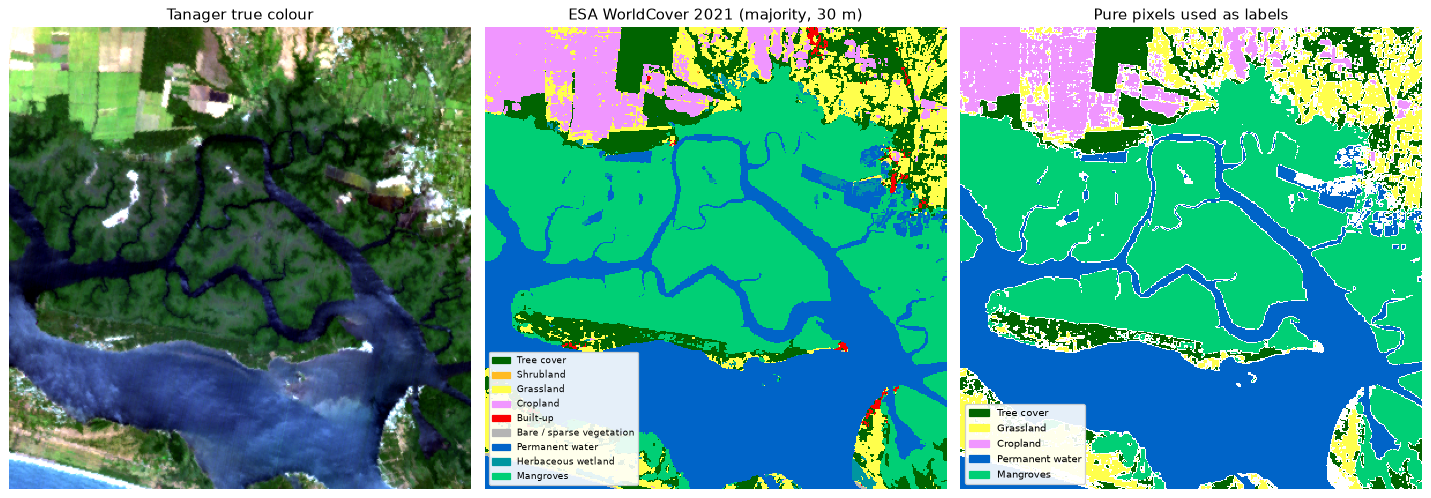

In [3]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

class_cmap = ListedColormap(COLORS)
class_cmap.set_bad("white")
legend = [Patch(color=c, label=n) for c, n in zip(COLORS, NAMES)]

def show_classes(ax, idx_map, title):
    # idx_map holds class indices 0..K-1, -1 / NaN = no class
    ax.imshow(np.ma.masked_less(idx_map, 0), cmap=class_cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest")
    ax.set_title(title); ax.axis("off")

wc_cmap, wc_norm, wc_legend = hu.label_cmap(np.unique(worldcover[worldcover > 0]))
fig, axes = plt.subplots(1, 3, figsize=(16, 5.6))
axes[0].imshow(hu.rgb_from_cube(cube, wl)); axes[0].set_title("Tanager true colour"); axes[0].axis("off")
axes[1].imshow(np.ma.masked_equal(worldcover, 0), cmap=wc_cmap, norm=wc_norm, interpolation="nearest")
axes[1].set_title("ESA WorldCover 2021 (majority, 30 m)"); axes[1].axis("off")
axes[1].legend(handles=wc_legend, fontsize=7, loc="lower left", framealpha=0.9)
show_classes(axes[2], y_map, "Pure pixels used as labels")
axes[2].legend(handles=legend, fontsize=8, loc="lower left", framealpha=0.9)
plt.tight_layout(); plt.show()

Notice that the pure-pixel labels are sparse along class boundaries (mangrove edges, field margins): mixed
pixels are exactly where a classifier will be least certain — keep that in mind when you read the uncertainty maps.

## 3. A spatial train / validation / test split with a buffer

We cut the window into **50 × 50 pixel blocks** (1.5 × 1.5 km) and randomly assign 60 % of the blocks to training,
20 % to validation (early stopping, model choice) and 20 % to testing (reported once, at the end).

Our patch model looks at a 9 × 9 neighbourhood (radius 4). A test pixel next to a block border would "see" training
pixels inside its patch, which leaks information. We therefore drop every pixel whose 9 × 9 neighbourhood touches
a block of another split — a **4-pixel buffer**.

class                train     val    test
Tree cover            5196    3041    2473
Grassland             6670    2400    1674
Cropland              2166    3596    2712
Permanent water      25310    5775    6765
Mangroves            33995    6154    8406


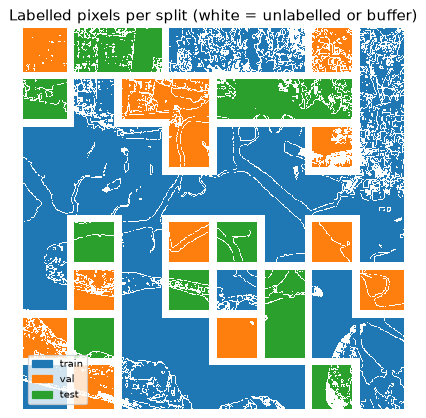

In [4]:
BLOCK = 50        # block size in pixels
R = 4             # patch radius → 9 × 9 patches

blocks = (np.arange(H) // BLOCK)[:, None] * (W // BLOCK) + (np.arange(W) // BLOCK)[None, :]
n_blocks = blocks.max() + 1
order = rng.permutation(n_blocks)
block_split = np.zeros(n_blocks, dtype=int)                    # 0 = train
block_split[order[int(0.6 * n_blocks):int(0.8 * n_blocks)]] = 1  # 1 = validation
block_split[order[int(0.8 * n_blocks):]] = 2                     # 2 = test
split_map = block_split[blocks]

# buffer: keep pixels whose (2R+1)×(2R+1) neighbourhood lies in a single split
same_split = minimum_filter(split_map, 2 * R + 1, mode="nearest") == maximum_filter(split_map, 2 * R + 1, mode="nearest")
labelled = (y_map >= 0) & same_split

SPLITS = ["train", "val", "test"]
print(f"{'class':18s}" + "".join(f"{s:>8s}" for s in SPLITS))
for k, n in enumerate(NAMES):
    print(f"{n:18s}" + "".join(f"{np.sum(labelled & (split_map == s) & (y_map == k)):8d}" for s in range(3)))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.imshow(np.where(labelled, split_map, np.nan), cmap=ListedColormap(["#1f77b4", "#ff7f0e", "#2ca02c"]),
          vmin=-0.5, vmax=2.5, interpolation="nearest")
ax.legend(handles=[Patch(color=c, label=s) for c, s in zip(["#1f77b4", "#ff7f0e", "#2ca02c"], SPLITS)],
          loc="lower left", fontsize=8)
ax.set_title("Labelled pixels per split (white = unlabelled or buffer)"); ax.axis("off"); plt.show()

### Label scarcity and class imbalance

In real projects you rarely have tens of thousands of labels. We therefore train on a **10 % random subset of the
training pixels**, keeping the natural class imbalance (mangrove and water dominate). Validation uses up to 500
pixels per class; the test set uses *all* test pixels.

In [5]:
def pixel_indices(split, frac=None, per_class=None):
    # (rows, cols) of labelled pixels in one split, optionally sub-sampled
    rows, cols = [], []
    for k in range(K):
        r, c = np.nonzero(labelled & (split_map == split) & (y_map == k))
        n = len(r)
        if frac is not None:
            n = max(1, int(frac * n))
        if per_class is not None:
            n = min(n, per_class)
        pick = rng.choice(len(r), size=n, replace=False)
        rows.append(r[pick]); cols.append(c[pick])
    return np.concatenate(rows), np.concatenate(cols)

idx_tr = pixel_indices(0, frac=0.10)
idx_va = pixel_indices(1, per_class=500)
idx_te = pixel_indices(2)

X_all = cube.transpose(1, 2, 0)                       # (H, W, bands) view for easy indexing
Xtr, ytr = X_all[idx_tr], y_map[idx_tr]
Xva, yva = X_all[idx_va], y_map[idx_va]
Xte, yte = X_all[idx_te], y_map[idx_te]
print("train", Xtr.shape, np.bincount(ytr), "\nval  ", Xva.shape, np.bincount(yva), "\ntest ", Xte.shape, np.bincount(yte))

train (7332, 352) [ 519  667  216 2531 3399] 
val   (2500, 352) [500 500 500 500 500] 
test  (22030, 352) [2473 1674 2712 6765 8406]


## 4. Baseline: Random Forest on the full spectrum

A Random Forest (Breiman 2001) needs no scaling, copes with hundreds of correlated bands and trains in seconds.
`class_weight="balanced_subsample"` compensates for the class imbalance.

In [6]:
t = time.time()
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=4, random_state=SEED)
rf.fit(Xtr, ytr)
p_rf = rf.predict(Xte)
print(f"RF trained in {time.time() - t:.1f} s")
print(f"Test overall accuracy {accuracy_score(yte, p_rf):.3f} | macro F1 {f1_score(yte, p_rf, average='macro'):.3f}")

RF trained in 2.5 s
Test overall accuracy 0.925 | macro F1 0.861


## 5. Model 1 — a 1D-CNN on spectra

A 1D convolutional network slides small filters **along the wavelength axis**. Early layers learn local shapes
(slopes, absorption dips such as the red edge or the 970/1200 nm water features); deeper layers combine them.

```
spectrum (352) → [Conv1d 7 → BN → ReLU → MaxPool] ×3 → AdaptiveAvgPool(8) → Dropout → Dense 64 → Dropout → Dense K
```

Ingredients that make it train well on small data:
- **Standardisation** of each band with the *training* mean and standard deviation (never use test statistics),
- **Class-weighted cross-entropy**: weight $w_k = N / (K\,N_k)$, so rare classes count as much as common ones,
- **Dropout** and **weight decay** against overfitting,
- **Early stopping**: keep the weights with the best *validation* macro-F1 and stop when it no longer improves.

In [7]:
band_mean, band_std = Xtr.mean(0), Xtr.std(0) + 1e-6

def standardise(X):
    return ((X - band_mean) / band_std).astype(np.float32)


class Spectral1DCNN(nn.Module):
    def __init__(self, n_classes, dropout=0.3):
        super().__init__()
        def block(cin, cout, k):
            return nn.Sequential(nn.Conv1d(cin, cout, k, padding=k // 2), nn.BatchNorm1d(cout), nn.ReLU(), nn.MaxPool1d(2))
        self.features = nn.Sequential(block(1, 16, 7), block(16, 32, 5), block(32, 64, 3), nn.AdaptiveAvgPool1d(8))
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(64 * 8, 64), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(64, n_classes))

    def forward(self, x):                   # x: (batch, bands)
        return self.head(self.features(x.unsqueeze(1)))


def predict_proba(model, X, batch=4096):
    # Softmax probabilities for an array (or a callable returning batches) of inputs
    model.eval()
    out = []
    with torch.inference_mode():
        for i in range(0, len(X), batch):
            xb = torch.as_tensor(X[i:i + batch]).to(DEVICE)
            out.append(torch.softmax(model(xb), dim=1).cpu().numpy())
    return np.concatenate(out)


def train_model(model, Xtr, ytr, Xva, yva, epochs=40, batch=128, lr=1e-3, patience=6):
    # Mini-batch training with class-weighted loss and early stopping on validation macro-F1
    model.to(DEVICE)
    counts = np.bincount(ytr, minlength=K)
    weights = torch.tensor(len(ytr) / (K * np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)
    loss_fn = nn.CrossEntropyLoss(weight=weights)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    Xt, yt = torch.as_tensor(Xtr), torch.as_tensor(ytr)
    best_f1, best_state, wait, history = -1.0, None, 0, []
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(Xt))
        total = 0.0
        for i in range(0, len(perm), batch):
            b = perm[i:i + batch]
            if len(b) < 2:                     # BatchNorm needs at least 2 samples
                continue
            opt.zero_grad()
            loss = loss_fn(model(Xt[b].to(DEVICE)), yt[b].to(DEVICE))
            loss.backward()
            opt.step()
            total += loss.item() * len(b)
        val_f1 = f1_score(yva, predict_proba(model, Xva).argmax(1), average="macro")
        history.append((total / len(perm), val_f1))
        if val_f1 > best_f1:
            best_f1, best_state, wait = val_f1, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    print(f"stopped after {epoch + 1} epochs, best validation macro-F1 = {best_f1:.3f}")
    return np.array(history)


torch.manual_seed(SEED)
cnn1d = Spectral1DCNN(K)
print(f"1D-CNN parameters: {sum(p.numel() for p in cnn1d.parameters()):,}")
t = time.time()
hist_1d = train_model(cnn1d, standardise(Xtr), ytr, standardise(Xva), yva)
print(f"trained in {time.time() - t:.0f} s")
p_1d = predict_proba(cnn1d, standardise(Xte)).argmax(1)
print(f"Test overall accuracy {accuracy_score(yte, p_1d):.3f} | macro F1 {f1_score(yte, p_1d, average='macro'):.3f}")

1D-CNN parameters: 42,309


stopped after 12 epochs, best validation macro-F1 = 0.875
trained in 41 s


Test overall accuracy 0.940 | macro F1 0.892


## 6. Model 2 — a spectral–spatial patch CNN (HybridSN-style)

**HybridSN** (Roy et al. 2020) first applies **3D convolutions** that slide over wavelength *and* space, then a
**2D convolution** over space only. To keep it small and fast we follow the original recipe and first compress the
spectra with **PCA** to 30 components (fitted on the *training* pixels only — fitting on all pixels would leak
information from the test blocks).

```
9×9×30 patch → Conv3d(8, 7×3×3) → Conv3d(16, 5×3×3) → reshape → Conv2d(64, 3×3) → Dense 128 → Dense K
```

In [8]:
N_PC = 30
pca = PCA(N_PC, random_state=SEED).fit(Xtr)
print(f"{N_PC} PCs explain {pca.explained_variance_ratio_.sum() * 100:.2f}% of the training-set variance")

def pca_image(cube_part):
    # (bands, h, w) cube → (N_PC, h, w) standardised PCA image; invalid pixels → 0 (the mean)
    pix, ok = hu.cube_to_pixels(cube_part)
    img = np.zeros((N_PC,) + ok.shape, dtype=np.float32)
    if ok.any():
        img[:, ok] = ((pca.transform(pix) - pc_mean) / pc_std).T
    return img

Ztr = pca.transform(Xtr)
pc_mean, pc_std = Ztr.mean(0), Ztr.std(0) + 1e-6
P = pca_image(cube)
P_pad = np.pad(P, ((0, 0), (R, R), (R, R)), mode="reflect")
patch_view = sliding_window_view(P_pad, (2 * R + 1, 2 * R + 1), axis=(1, 2))  # (N_PC, H, W, 9, 9), no copy

def get_patches(rows, cols):
    return np.ascontiguousarray(patch_view[:, rows, cols].transpose(1, 0, 2, 3))   # (n, N_PC, 9, 9)

Ptr, Pva, Pte = get_patches(*idx_tr), get_patches(*idx_va), get_patches(*idx_te)
print("patch tensors:", Ptr.shape, Pva.shape, Pte.shape)

30 PCs explain 99.99% of the training-set variance
patch tensors: (7332, 30, 9, 9) (2500, 30, 9, 9) (22030, 30, 9, 9)


In [9]:
class HybridSN(nn.Module):
    # A small HybridSN-style network: 3D convolutions (spectral-spatial) → 2D convolution (spatial)
    def __init__(self, n_classes, n_bands=N_PC, patch=2 * R + 1, dropout=0.4):
        super().__init__()
        self.conv3d = nn.Sequential(
            nn.Conv3d(1, 8, (7, 3, 3)), nn.BatchNorm3d(8), nn.ReLU(),
            nn.Conv3d(8, 16, (5, 3, 3)), nn.BatchNorm3d(16), nn.ReLU())
        depth, size = n_bands - 6 - 4, patch - 4          # shape left after the two 3D convolutions
        self.conv2d = nn.Sequential(nn.Conv2d(16 * depth, 64, 3), nn.BatchNorm2d(64), nn.ReLU())
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(64 * (size - 2) ** 2, 128),
                                  nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, n_classes))

    def forward(self, x):                          # x: (batch, bands, 9, 9)
        z = self.conv3d(x.unsqueeze(1))            # (batch, 16, depth, 5, 5)
        z = z.flatten(1, 2)                        # merge filters × depth into channels
        return self.head(self.conv2d(z))


torch.manual_seed(SEED)
hybrid = HybridSN(K)
print(f"HybridSN parameters: {sum(p.numel() for p in hybrid.parameters()):,}")
t = time.time()
hist_3d = train_model(hybrid, Ptr, ytr, Pva, yva, epochs=30, patience=5)
print(f"trained in {time.time() - t:.0f} s")
p_3d = predict_proba(hybrid, Pte).argmax(1)
print(f"Test overall accuracy {accuracy_score(yte, p_3d):.3f} | macro F1 {f1_score(yte, p_3d, average='macro'):.3f}")

HybridSN parameters: 265,349


stopped after 12 epochs, best validation macro-F1 = 0.927
trained in 35 s


Test overall accuracy 0.959 | macro F1 0.925


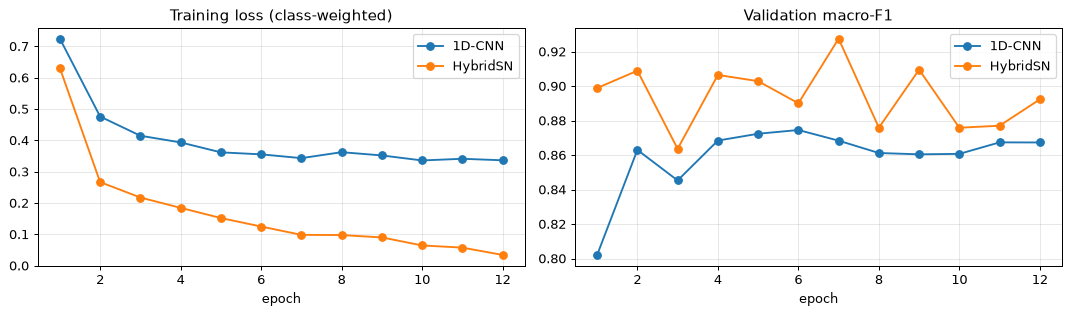

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for h, name in ((hist_1d, "1D-CNN"), (hist_3d, "HybridSN")):
    axes[0].plot(np.arange(1, len(h) + 1), h[:, 0], marker="o", label=name)
    axes[1].plot(np.arange(1, len(h) + 1), h[:, 1], marker="o", label=name)
axes[0].set(title="Training loss (class-weighted)", xlabel="epoch")
axes[1].set(title="Validation macro-F1", xlabel="epoch")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

Early stopping restores the epoch with the best validation score, so the curves may continue a few epochs past
the model we actually keep. If validation F1 jumps around a lot, the validation set is small or unrepresentative —
another reason to report results on a separate test set.

## 7. Honest comparison on the test blocks

,Random Forest,1D-CNN,HybridSN (patches)
Tree cover,0.836,0.830,0.882
Grassland,0.646,0.720,0.804
Cropland,0.851,0.940,0.960
Permanent water,0.995,0.994,0.994
Mangroves,0.979,0.974,0.983
macro F1,0.861,0.892,0.925
overall accuracy,0.925,0.940,0.959


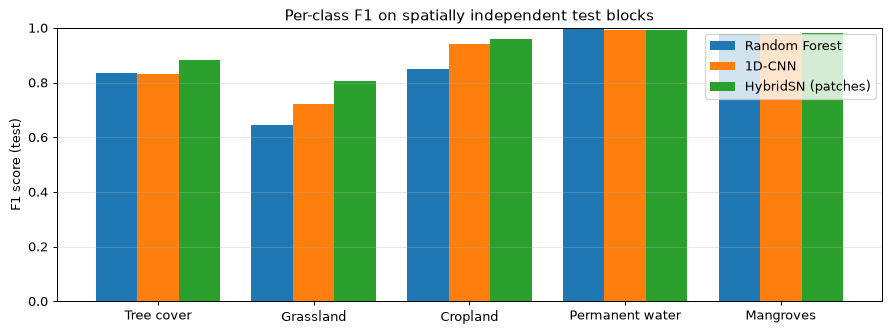

In [11]:
import pandas as pd

results = {"Random Forest": p_rf, "1D-CNN": p_1d, "HybridSN (patches)": p_3d}
table = pd.DataFrame({m: f1_score(yte, p, average=None) for m, p in results.items()}, index=NAMES).round(3)
table.loc["macro F1"] = [f1_score(yte, p, average="macro") for p in results.values()]
table.loc["overall accuracy"] = [accuracy_score(yte, p) for p in results.values()]
display(table.round(3))

ax = table.iloc[:K].plot.bar(figsize=(10, 3.8), rot=0, width=0.8)
ax.set(ylabel="F1 score (test)", ylim=(0, 1), title="Per-class F1 on spatially independent test blocks")
ax.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

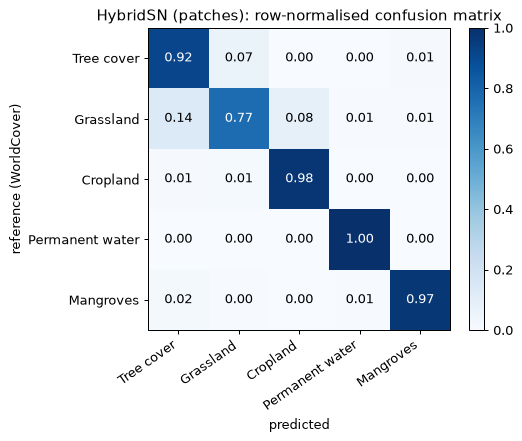

In [12]:
best_name = table.loc["macro F1"].idxmax()
cm = confusion_matrix(yte, results[best_name], labels=range(K), normalize="true")
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(K):
    for j in range(K):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
ax.set_xticks(range(K)); ax.set_xticklabels(NAMES, rotation=35, ha="right")
ax.set_yticks(range(K)); ax.set_yticklabels(NAMES)
ax.set(xlabel="predicted", ylabel="reference (WorldCover)", title=f"{best_name}: row-normalised confusion matrix")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

**How to read this.** Water and mangroves are spectrally distinctive and near-perfect for every model. The hard
classes are the *vegetation* classes — tropical tree cover, grassland and cropland — which overlap spectrally
and are also where WorldCover itself is least reliable. Differences of 1–2 F1 points between models are within the
noise of one random split: before claiming that model A beats model B, repeat the experiment with several block
assignments (or spatial cross-validation, notebook 21).

## 8. From model to map

A classifier only becomes useful once it produces a **map**. We predict every valid pixel of the window with all
three models and also show the **confidence** of the patch model — the largest softmax probability. Note that the
models are forced to choose one of the five classes, even for built-up areas, wetlands or bare sand that were never
in the training data (the *open-set* problem).

In [13]:
t = time.time()
rows_v, cols_v = np.nonzero(finite)
X_valid = X_all[rows_v, cols_v]

def to_map(values, fill=np.nan):
    out = np.full((H, W), fill, dtype=float)
    out[rows_v, cols_v] = values
    return out

map_rf = to_map(rf.predict(X_valid))
map_1d = to_map(predict_proba(cnn1d, standardise(X_valid)).argmax(1))

prob_3d = np.concatenate([predict_proba(hybrid, get_patches(rows_v[i:i + 8192], cols_v[i:i + 8192]))
                          for i in range(0, len(rows_v), 8192)])
map_3d, conf_3d = to_map(prob_3d.argmax(1)), to_map(prob_3d.max(1))
print(f"predicted {len(rows_v):,} pixels × 3 models in {time.time() - t:.0f} s")

predicted 160,000 pixels × 3 models in 74 s


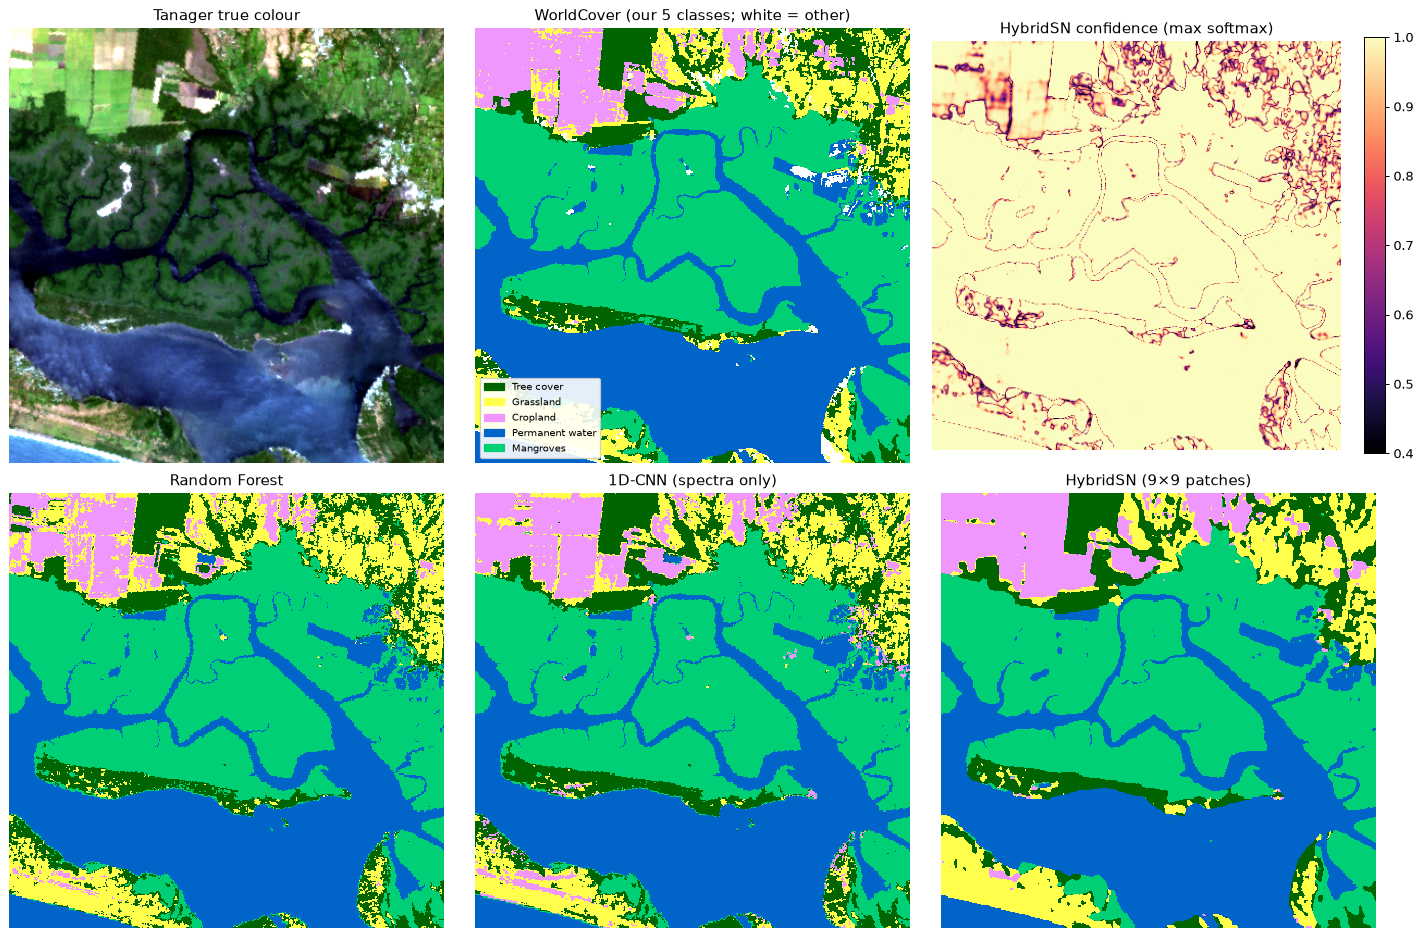

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10.5))
axes[0, 0].imshow(hu.rgb_from_cube(cube, wl)); axes[0, 0].set_title("Tanager true colour"); axes[0, 0].axis("off")
wc_idx = np.full((H, W), -1)
for k, code in enumerate(CLASSES):
    wc_idx[worldcover == code] = k
show_classes(axes[0, 1], wc_idx, "WorldCover (our 5 classes; white = other)")
axes[0, 1].legend(handles=legend, fontsize=8, loc="lower left", framealpha=0.9)
im = axes[0, 2].imshow(conf_3d, cmap="magma", vmin=0.4, vmax=1)
axes[0, 2].set_title("HybridSN confidence (max softmax)"); axes[0, 2].axis("off")
plt.colorbar(im, ax=axes[0, 2], fraction=0.046)
show_classes(axes[1, 0], np.nan_to_num(map_rf, nan=-1), "Random Forest")
show_classes(axes[1, 1], np.nan_to_num(map_1d, nan=-1), "1D-CNN (spectra only)")
show_classes(axes[1, 2], np.nan_to_num(map_3d, nan=-1), "HybridSN (9×9 patches)")
plt.tight_layout(); plt.show()

**What to look for**
- The **pixel models** (RF, 1D-CNN) produce speckle ("salt-and-pepper") inside fields and forests; the **patch
  model** gives smoother, more map-like results but can blur narrow features such as creeks and field edges.
- **Low confidence** concentrates on boundaries, mixed pixels and on materials that are not in the legend
  (villages, sand bars, wetlands). Confidence is *not* calibrated probability: a softmax can be confidently wrong.

## 9. MC-dropout uncertainty

**Monte-Carlo dropout** (Gal & Ghahramani 2016) keeps dropout switched on at prediction time and runs the model
several times. Each run drops different neurons, so the predictions differ; the spread tells us how uncertain the
model is. We summarise it with the **predictive entropy** $H = -\sum_k \bar p_k \log \bar p_k$ of the mean
probabilities (0 = certain, $\log K$ = completely unsure).

10 stochastic passes over 16,900 pixels in 32 s


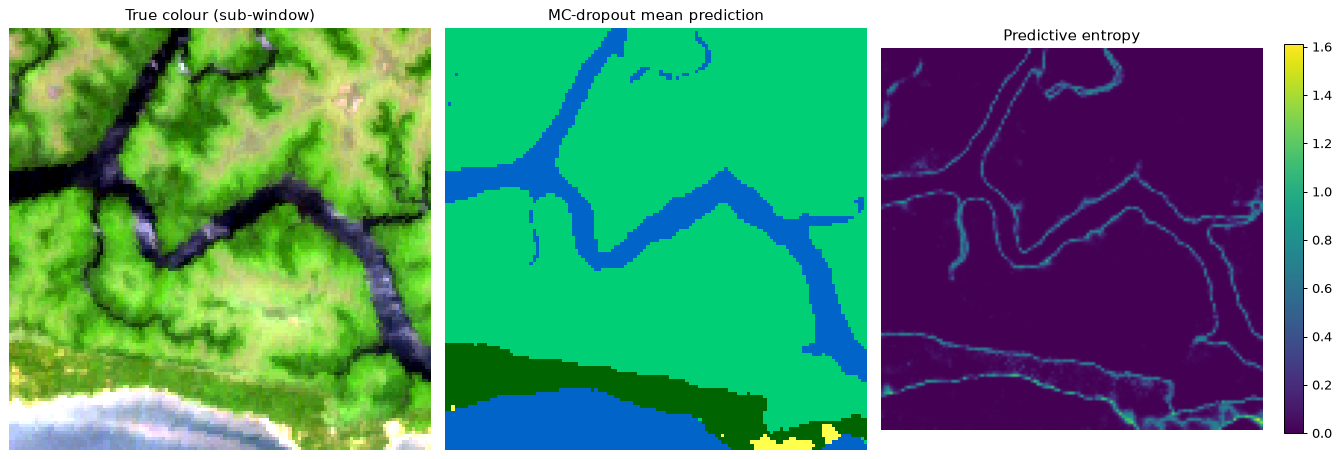

In [15]:
def mc_dropout_proba(model, patches, n_passes=10, batch=4096):
    model.eval()
    for m in model.modules():                 # switch ONLY dropout back to training mode
        if isinstance(m, nn.Dropout):
            m.train()
    runs = []
    with torch.inference_mode():
        for _ in range(n_passes):
            runs.append(np.concatenate([torch.softmax(model(torch.as_tensor(patches[i:i + batch]).to(DEVICE)), 1).cpu().numpy()
                                        for i in range(0, len(patches), batch)]))
    model.eval()
    return np.stack(runs)                     # (passes, n, K)

SUB = (160, 290, 110, 240)                    # 130 × 130 sub-window inside WINDOW (local pixel coordinates)
rr, cc = np.mgrid[SUB[0]:SUB[1], SUB[2]:SUB[3]]
sub_ok = finite[rr, cc]
t = time.time()
runs = mc_dropout_proba(hybrid, get_patches(rr[sub_ok], cc[sub_ok]))
mean_p = runs.mean(0)
entropy = -(mean_p * np.log(mean_p + 1e-9)).sum(1)
print(f"{runs.shape[0]} stochastic passes over {sub_ok.sum():,} pixels in {time.time() - t:.0f} s")

ent_map = np.full(rr.shape, np.nan); ent_map[sub_ok] = entropy
cls_map = np.full(rr.shape, -1); cls_map[sub_ok] = mean_p.argmax(1)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(hu.rgb_from_cube(cube[:, SUB[0]:SUB[1], SUB[2]:SUB[3]], wl)); axes[0].set_title("True colour (sub-window)")
show_classes(axes[1], cls_map, "MC-dropout mean prediction")
im = axes[2].imshow(ent_map, cmap="viridis", vmin=0, vmax=np.log(K)); axes[2].set_title("Predictive entropy")
plt.colorbar(im, ax=axes[2], fraction=0.046)
for ax in axes:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 10. Sliding-window (tiled) inference over the full scene

A whole Tanager cube (≈ 650 × 785 pixels × 352 bands) is about 0.75 GB in memory — fine on a workstation, but
real archives are much bigger. The standard solution is **tiled inference**: read one strip of rows at a time,
add a **halo** of $R$ rows above and below so patches at tile edges see their real neighbours, predict the core
rows, and write the result into the output map. The exact same code scales to hundreds of scenes.

In [16]:
def predict_scene_tiled(scene, model, tile_rows=64):
    # Predict class index and confidence for every valid pixel of a scene, one strip of rows at a time
    n_rows, n_cols = scene.shape[1], scene.shape[2]
    classes = np.full((n_rows, n_cols), -1, dtype=np.int16)
    confidence = np.full((n_rows, n_cols), np.nan, dtype=np.float32)
    for r0 in range(0, n_rows, tile_rows):
        r1 = min(n_rows, r0 + tile_rows)
        h0, h1 = max(0, r0 - R), min(n_rows, r1 + R)              # rows read, including the halo
        tile, _ = scene.read_cube((h0, h1, 0, n_cols))
        valid = np.all(np.isfinite(tile), axis=0)
        img = pca_image(tile)
        img = np.pad(img, ((0, 0), (R - (r0 - h0), R - (h1 - r1)), (R, R)), mode="reflect")
        view = sliding_window_view(img, (2 * R + 1, 2 * R + 1), axis=(1, 2))
        core_valid = valid[r0 - h0:r0 - h0 + (r1 - r0)]
        rows, cols = np.nonzero(core_valid)
        if len(rows) == 0:
            continue
        probs = np.concatenate([predict_proba(model, np.ascontiguousarray(view[:, rows[i:i + 8192], cols[i:i + 8192]].transpose(1, 0, 2, 3)))
                                for i in range(0, len(rows), 8192)])
        classes[r0 + rows, cols] = probs.argmax(1)
        confidence[r0 + rows, cols] = probs.max(1)
    return classes, confidence

t = time.time()
full_cls, full_conf = predict_scene_tiled(scene, hybrid)
print(f"full scene {scene.shape[1]}×{scene.shape[2]} px predicted in {time.time() - t:.0f} s")

# Export: WorldCover codes (0 = no data) and confidence in percent, both as Cloud-Optimised GeoTIFFs
out_dir = hu.ensure_output_dir("20")
codes = np.where(full_cls >= 0, np.array(CLASSES)[np.clip(full_cls, 0, K - 1)], 0).astype("uint8")
conf_pct = np.where(np.isfinite(full_conf), np.round(full_conf * 100), 0).astype("uint8")
f1 = hu.save_geotiff(out_dir / f"{SCENE_ID}_hybridsn_classes.tif", codes, scene.transform(), scene.crs,
                     nodata=0, band_names=["worldcover_code"])
f2 = hu.save_geotiff(out_dir / f"{SCENE_ID}_hybridsn_confidence.tif", conf_pct, scene.transform(), scene.crs,
                     nodata=0, band_names=["confidence_percent"])
print("saved:", f1.name, "and", f2.name)

full scene 655×785 px predicted in 88 s
saved: 20250223_165546_32_4001_hybridsn_classes.tif and 20250223_165546_32_4001_hybridsn_confidence.tif


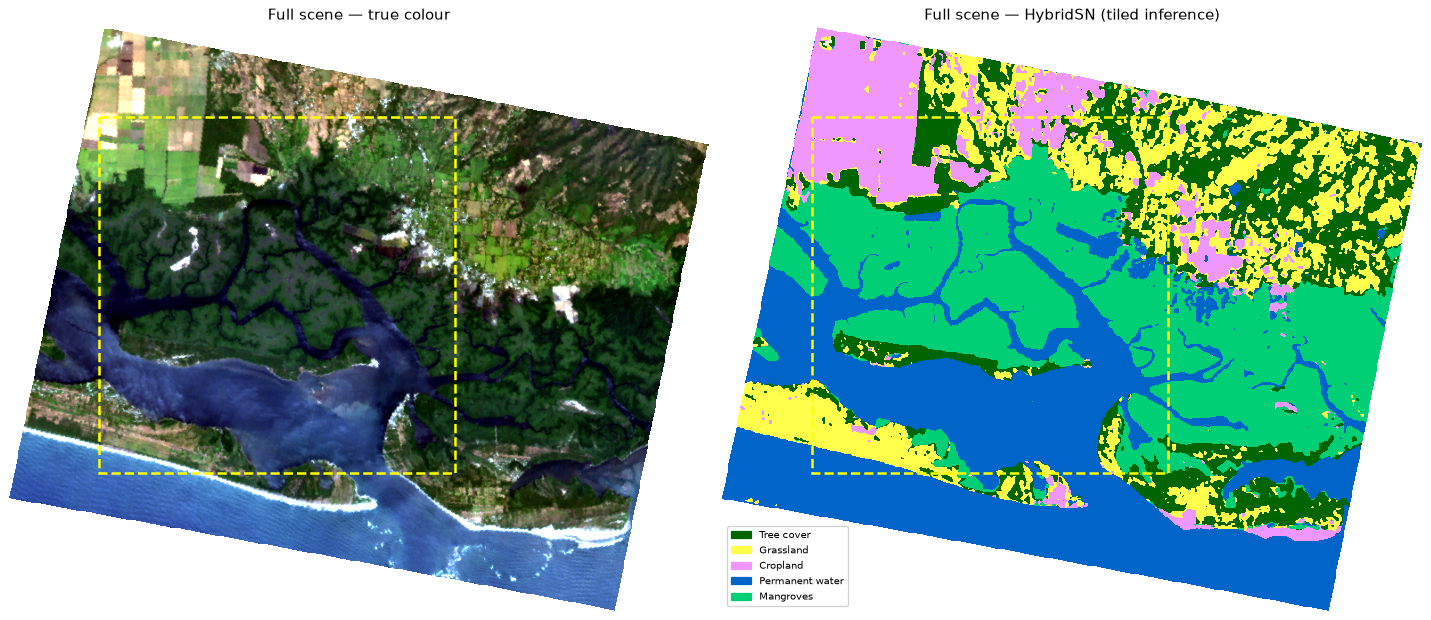

Yellow box = the training window.


In [17]:
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].imshow(scene.rgb(stride=1)); axes[0].set_title("Full scene — true colour")
show_classes(axes[1], full_cls, "Full scene — HybridSN (tiled inference)")
axes[1].legend(handles=legend, fontsize=8, loc="lower left", framealpha=0.9)
for ax in axes:
    ax.add_patch(Rectangle((WINDOW[2], WINDOW[0]), WINDOW[3] - WINDOW[2], WINDOW[1] - WINDOW[0],
                           fill=False, ec="yellow", lw=2, ls="--"))
    ax.axis("off")
plt.tight_layout(); plt.show()
print("Yellow box = the training window.")

## 11. Domain shift — does the model travel?

We test two kinds of "new data", always with WorldCover pure pixels as reference:

1. **Same scene, outside the training window** (spatial extrapolation, same acquisition),
2. **A different scene**: Ho Chi Minh City, Vietnam — different country, climate, date and atmosphere. It has
   tree cover, grassland, cropland (mostly rice) and water, but no mangroves in WorldCover.

In [18]:
lab_full, pur_full = hu.load_labels(SCENE_ID)
outside = np.ones(lab_full.shape, bool)
outside[WINDOW[0] - R:WINDOW[1] + R, WINDOW[2] - R:WINDOW[3] + R] = False
ref_idx = np.full(lab_full.shape, -1)
for k, code in enumerate(CLASSES):
    ref_idx[(lab_full == code) & (pur_full == 9)] = k
sel = outside & (ref_idx >= 0) & (full_cls >= 0)
print(f"Outside the training window: {sel.sum():,} reference pixels")
print(f"  overall accuracy {accuracy_score(ref_idx[sel], full_cls[sel]):.3f}   (test blocks: {table.loc['overall accuracy', 'HybridSN (patches)']:.3f})")
print(f"  macro F1         {f1_score(ref_idx[sel], full_cls[sel], average='macro'):.3f}   (test blocks: {table.loc['macro F1', 'HybridSN (patches)']:.3f})")

Outside the training window: 174,309 reference pixels
  overall accuracy 0.843   (test blocks: 0.959)
  macro F1         0.792   (test blocks: 0.925)


In [19]:
HCMC_ID = "20250407_035509_25_4001"
HCMC_WINDOW = (200, 500, 200, 500)
hcmc = hu.get_scene(HCMC_ID)
assert np.allclose(hcmc.wavelengths, scene.wavelengths), "band grids differ — resample first"
cube_h, _ = hcmc.read_cube(HCMC_WINDOW)
lab_h, pur_h = hu.load_labels(HCMC_ID, HCMC_WINDOW, min_purity=9)

SHARED = [10, 30, 40, 80]
ref_h = np.full(lab_h.shape, -1)
for code in SHARED:
    ref_h[lab_h == code] = CLASSES.index(code)
ok_h = (ref_h >= 0) & np.all(np.isfinite(cube_h), axis=0)
rows_h, cols_h = np.nonzero(ok_h)
Xh = cube_h[:, rows_h, cols_h].T
yh = ref_h[rows_h, cols_h]

Ph = np.pad(pca_image(cube_h), ((0, 0), (R, R), (R, R)), mode="reflect")
view_h = sliding_window_view(Ph, (2 * R + 1, 2 * R + 1), axis=(1, 2))
Ph_patches = np.ascontiguousarray(view_h[:, rows_h, cols_h].transpose(1, 0, 2, 3))

pred_h = {"Random Forest": rf.predict(Xh),
          "1D-CNN": predict_proba(cnn1d, standardise(Xh)).argmax(1),
          "HybridSN (patches)": predict_proba(hybrid, Ph_patches).argmax(1)}
shift = pd.DataFrame({m: {"El Salvador test OA": table.loc["overall accuracy", m],
                          "Ho Chi Minh City OA": accuracy_score(yh, p),
                          "HCMC pixels predicted as mangrove": np.mean(p == CLASSES.index(95))}
                      for m, p in pred_h.items()}).T
display(shift.round(3))

,El Salvador test OA,Ho Chi Minh City OA,HCMC pixels predicted as mangrove
Random Forest,0.925,0.261,0.412
1D-CNN,0.940,0.334,0.436
HybridSN (patches),0.959,0.335,0.000


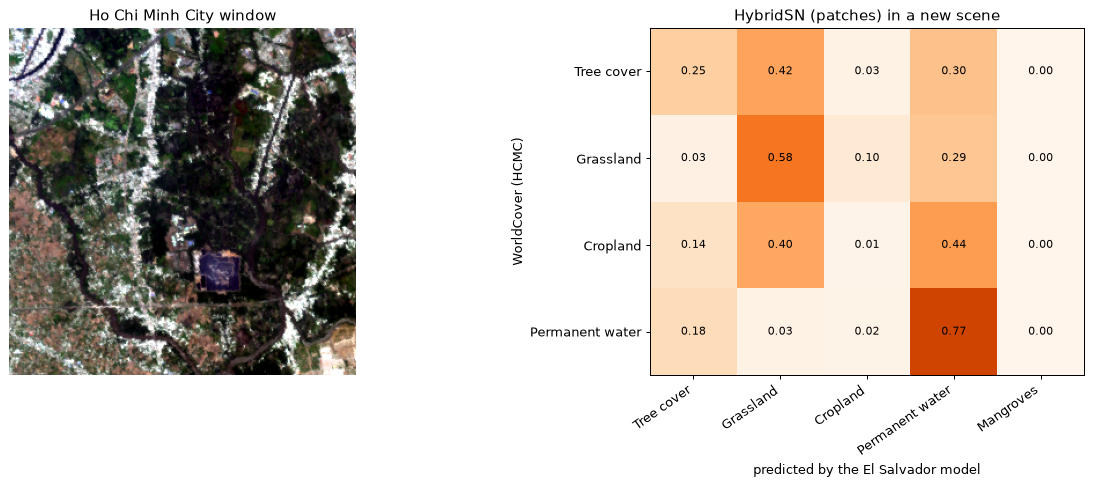

In [20]:
m_best = shift["Ho Chi Minh City OA"].idxmax()
cm_h = confusion_matrix(yh, pred_h[m_best], labels=range(K))
cm_h = cm_h[[CLASSES.index(c) for c in SHARED]]              # rows: shared classes only
cm_h = cm_h / cm_h.sum(1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.35]})
axes[0].imshow(hu.rgb_from_cube(cube_h, wl)); axes[0].set_title("Ho Chi Minh City window"); axes[0].axis("off")
im = axes[1].imshow(cm_h, cmap="Oranges", vmin=0, vmax=1)
for i in range(cm_h.shape[0]):
    for j in range(K):
        axes[1].text(j, i, f"{cm_h[i, j]:.2f}", ha="center", va="center", fontsize=9)
axes[1].set_xticks(range(K)); axes[1].set_xticklabels(NAMES, rotation=35, ha="right")
axes[1].set_yticks(range(len(SHARED))); axes[1].set_yticklabels([hu.WORLDCOVER_CLASSES[c][0] for c in SHARED])
axes[1].set(xlabel="predicted by the El Salvador model", ylabel="WorldCover (HCMC)", title=f"{m_best} in a new scene")
plt.tight_layout(); plt.show()

**Read the table and the matrix together.** The *pixel* models label a large share of Ho Chi Minh City as
**mangrove** — a class that does not occur in this window — because dense urban trees and wet vegetation resemble the
only dense, wet vegetation they have seen. The patch model avoids that mistake but confuses the vegetation classes and
sends many cropland pixels to *water*. Overall accuracy collapses for every model.

**Why does accuracy drop?**
- **Different "cropland".** In El Salvador it is mostly sugar cane; around Ho Chi Minh City it is rice paddies —
  often flooded, so they look like (vegetated) water. Same label, different spectra.
- **Different acquisitions**: sun angle, atmosphere (haze, water vapour), and viewing geometry change the
  retrieved reflectance slightly; PCA features and the band standardisation were fitted on El Salvador only.
- **Different backgrounds and mixtures**: urban trees, shade and roofs create spectra that never occurred in training.
- **Open-set errors**: classes that the model does not know (e.g. built-up) must be forced into a known class.

**What helps in practice:** train on labels from *several* scenes and seasons; add a few labels from the new area
and **fine-tune**; use per-scene normalisation or domain-adaptation methods; start from a **pre-trained
(foundation) model**; and always validate in the area where the map will be used.

## 12. Optional: a classic benchmark (Indian Pines)

Most hyperspectral deep-learning papers report results on small airborne benchmarks such as **Indian Pines**
(AVIRIS, 145 × 145 px, 200 bands, 16 classes) or **Pavia University** (ROSIS, 103 bands). They are useful for
comparing with the literature, but beware: many published numbers use *random pixel splits* on a single tiny image and
are therefore strongly inflated by spatial autocorrelation.

Set `RUN_BENCHMARK = True` to try it. The files are downloaded from the Grupo de Inteligencia Computacional (UPV/EHU)
website; if the download is blocked on your network, download `Indian_pines_corrected.mat` and `Indian_pines_gt.mat`
manually into `data/benchmarks/`.

In [ ]:
RUN_BENCHMARK = True   # set to True to download (~6 MB) and train on Indian Pines

if RUN_BENCHMARK:
    import requests
    from scipy.io import loadmat
    bench_dir = hu.DATA_DIR / "benchmarks"
    bench_dir.mkdir(parents=True, exist_ok=True)
    files = {"Indian_pines_corrected.mat": "https://www.ehu.eus/ccwintco/uploads/6/67/Indian_pines_corrected.mat",
             "Indian_pines_gt.mat": "https://www.ehu.eus/ccwintco/uploads/c/c4/Indian_pines_gt.mat"}
    for name, url in files.items():
        if not (bench_dir / name).exists():
            r = requests.get(url, timeout=120, headers={"User-Agent": "Mozilla/5.0"})
            r.raise_for_status()
            (bench_dir / name).write_bytes(r.content)

    def first_array(path):
        d = loadmat(path)
        return next(v for k, v in d.items() if not k.startswith("__"))

    ip_cube = first_array(bench_dir / "Indian_pines_corrected.mat").astype(np.float32)   # (145, 145, 200)
    ip_gt = first_array(bench_dir / "Indian_pines_gt.mat").astype(int)                  # 0 = unlabelled
    Xip, yip = ip_cube[ip_gt > 0], ip_gt[ip_gt > 0] - 1
    # Spatial split: left 60 % of columns = train, next 20 % = validation, right 20 % = test
    cols = np.nonzero(ip_gt > 0)[1]
    tr_ip, va_ip, te_ip = cols < 87, (cols >= 87) & (cols < 116), cols >= 116
    mu_ip, sd_ip = Xip[tr_ip].mean(0), Xip[tr_ip].std(0) + 1e-6
    n_ip = int(yip.max()) + 1
    K_saved, K = K, n_ip                              # train_model uses the global K for class weights
    net_ip = Spectral1DCNN(n_ip)
    train_model(net_ip, (Xip[tr_ip] - mu_ip) / sd_ip, yip[tr_ip], (Xip[va_ip] - mu_ip) / sd_ip, yip[va_ip], epochs=60)
    K = K_saved
    p_ip = predict_proba(net_ip, ((Xip[te_ip] - mu_ip) / sd_ip).astype(np.float32)).argmax(1)
    present = np.unique(yip[te_ip])
    print(f"Indian Pines, spatial split — OA {accuracy_score(yip[te_ip], p_ip):.3f}, "
          f"macro F1 over the {len(present)} classes present in the test strip "
          f"{f1_score(yip[te_ip], p_ip, labels=present, average='macro'):.3f}")
else:
    print("Benchmark skipped (RUN_BENCHMARK = False).")

Benchmark skipped (RUN_BENCHMARK = False).


## ✏️ Your turn

**1. Patch size.** Change `R` to 2 (5 × 5 patches) and 6 (13 × 13) — remember the buffer changes too — and rerun
Sections 3–8. How do the test F1 and the smoothness of the map change? Where do larger patches hurt?

<details><summary>Hint</summary>

`R` is used by the buffer (Section 3), the patch extraction (Section 6) and `HybridSN(patch=2*R+1)`. Re-run everything
from Section 3 downwards after changing it. Look closely at narrow creeks in the mangroves.
</details>

<details><summary>Solution</summary>

```python
R = 6   # then re-run the notebook from Section 3
# Typical outcome: slightly higher F1 for large homogeneous classes, but narrow features (creeks, field
# margins) disappear and boundary pixels get the majority class of their neighbourhood.
```
</details>

**2. The price of a random split.** Replace the block split by a *random pixel* split (`split_map = rng.integers(0, 3, (H, W))`,
no buffer) and retrain the HybridSN. Compare the test accuracy with the block-split result. Which number would you
trust for a map of a *new* area?

<details><summary>Hint</summary>

With random pixels, the 9 × 9 patches of test pixels overlap with training patches — the network has literally seen
most of the test pixels' neighbourhood during training.
</details>

<details><summary>Solution</summary>

```python
split_map = rng.integers(0, 3, size=(H, W))
same_split = np.ones((H, W), bool)          # no buffer
labelled = (y_map >= 0) & same_split
# re-run Sections 3 (from `idx_tr = ...`), 6 and 7 → test accuracy typically rises by several points.
# The block-split number is the honest estimate for new areas (see notebook 21 for spatial cross-validation).
```
</details>

**3. Learning curve.** Train the RF and the 1D-CNN with 1 %, 3 %, 10 % and 30 % of the training pixels and plot
macro-F1 against the number of labels. At which label budget does deep learning start to pay off (if at all)?

<details><summary>Solution</summary>

```python
fracs, f_rf, f_cnn = [0.01, 0.03, 0.10, 0.30], [], []
for frac in fracs:
    r_, c_ = pixel_indices(0, frac=frac)
    Xf, yf = X_all[r_, c_], y_map[r_, c_]
    f_rf.append(f1_score(yte, RandomForestClassifier(300, class_weight="balanced_subsample", n_jobs=4,
                                                     random_state=SEED).fit(Xf, yf).predict(Xte), average="macro"))
    net = Spectral1DCNN(K)
    train_model(net, standardise(Xf), yf, standardise(Xva), yva)
    f_cnn.append(f1_score(yte, predict_proba(net, standardise(Xte)).argmax(1), average="macro"))
plt.semilogx([int(f * np.sum(labelled & (split_map == 0))) for f in fracs], f_rf, "o-", label="RF")
plt.semilogx([int(f * np.sum(labelled & (split_map == 0))) for f in fracs], f_cnn, "s-", label="1D-CNN")
plt.xlabel("training pixels"); plt.ylabel("test macro-F1"); plt.legend(); plt.grid(alpha=.3)
```
</details>

**4. Fine-tuning for a new place.** Take 50 labelled pixels per shared class from the Ho Chi Minh City window,
continue training the 1D-CNN on them for a few epochs (small learning rate, e.g. `lr=1e-4`), and evaluate on the
*remaining* HCMC pixels. How much of the domain-shift loss do you recover?

<details><summary>Hint</summary>

Copy the model first (`copy.deepcopy(cnn1d)`) so you can compare. Use a spatially separate part of the HCMC window
for evaluation, otherwise the result is optimistic. Remember that the HCMC data contain no mangroves.
</details>

**5. Uncertainty as a quality flag.** Using `conf_3d`, compute the test accuracy for pixels with confidence
> 0.9 and < 0.6. Would you publish a map with a "low confidence" mask? How would an end user use it?

## Key takeaways

- Start every project with a **strong, simple baseline** (Random Forest). Deep models must beat it on a
  **spatially independent** test set to be worth their complexity.
- **1D-CNNs** learn from spectral shape; **patch CNNs** add spatial context and produce smoother maps, but need a
  buffer between training and test areas to avoid leakage.
- Deliver **maps with an uncertainty layer** (confidence or MC-dropout entropy) — users need to know where not to trust the map.
- Scale up with **tiled inference**; export results as **COGs** so they can be served in a web map or GIS.
- Expect accuracy to drop under **domain shift**. Validate where the map will be used, add local labels, and
  consider pre-trained / foundation models.

**For your project:** reuse `train_model`, `predict_proba` and `predict_scene_tiled`; report RF and deep-learning
results side by side, with spatial splits (notebook 21), and include an uncertainty map in your final presentation.

**References:** Breiman (2001) *Machine Learning* 45 · Chen et al. (2016) *IEEE TGRS* 54 — 3D-CNN for HSI ·
Roy et al. (2020) *IEEE GRSL* 17 — HybridSN · Gal & Ghahramani (2016) *ICML* — MC dropout ·
Roberts et al. (2017) *Ecography* 40 — cross-validation for structured data · Ploton et al. (2020) *Nature Communications* 11 ·
Hong et al. (2022) *IEEE TGRS* 60 — SpectralFormer · Zanaga et al. (2022) — ESA WorldCover 10 m 2021 v200.

---
> 📖 Data: Tanager — CC-BY-4.0 © Planet Labs PBC · ESA WorldCover 2021 v200 — CC-BY 4.0

In [22]:
print(f"Notebook runtime: {(time.time() - T_START) / 60:.1f} min")

Notebook runtime: 5.1 min
